# Huấn luyện và Đánh giá SVM & UMAP trên DSADS (Machine Learning Baseline)

Notebook này triển khai toàn bộ nhánh Machine Learning truyền thống trong đề tài nghiên cứu:
1. **Trích xuất 315 đặc trưng thống kê miền thời gian** từ 45 kênh tín hiệu cảm biến (7 đặc trưng x 45 kênh).
2. **Kiểm chứng chéo theo đối tượng (GroupKFold CV)** trên 5 người tập Train (`p1`–`p5`) để đánh giá độ tổng quát hóa và chống rò rỉ dữ liệu.
3. **Huấn luyện mô hình SVM Baseline (RBF kernel)** với siêu tham số $C=3.0, \gamma=0.0015$ đã được tối ưu qua Grid Search.
4. **Khảo sát kỹ thuật giảm chiều UMAP** (nén từ 315 xuống 20 chiều) kết hợp với SVM để đo lường mức độ suy giảm thông tin phân loại.
5. **Trực quan hóa không gian đặc trưng UMAP 2D** và phân tích ma trận nhầm lẫn (Confusion Matrix).
6. **Lưu trữ các artifacts mô hình** (`.joblib`) phục vụ trực tiếp cho ứng dụng Web Demo và đối chiếu kết quả.

### Sơ đồ quy trình thực nghiệm Machine Learning
![Sơ đồ thực nghiệm SVM và UMAP](../reports/figures/diagram_svm_umap_pipeline.png)

<details>
<summary><b>Xem mã nguồn luồng xử lý (Mermaid)</b></summary>

```mermaid
flowchart LR
    A["Dữ liệu thô (N, 125, 45)"] --> B["Trích xuất 315 đặc trưng\n(mean, std, min, max, median, skew, kurt)"]
    B --> C["StandardScaler\n(Fit duy nhất trên Train)"]
    C --> D1["Nhánh SVM Baseline (315 chiều)\nKernel RBF: C=3.0, γ=0.0015"]
    C --> D2["Nhánh UMAP (20 chiều) + SVM\nNén 94% số chiều"]
    C --> D3["Nhánh UMAP 2D\nTrực quan hóa 19 cụm hoạt động"]
```
</details>


In [1]:
# Tự động nhận diện môi trường: Google Colab hay Local VS Code / Jupyter
try:
    import google.colab  # type: ignore
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
    print("Môi trường: Google Colab (Đã kết nối Google Drive thành công)")
except ImportError:
    print("Môi trường: Local VS Code / Jupyter")

import os
import sys
import importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import umap
import joblib

# Tìm kiếm thư mục gốc dự án an toàn trên mọi môi trường (bất kể cwd ở đâu)
def find_project_root():
    current = Path.cwd().resolve()
    for p in [current, *current.parents]:
        if (p / 'src' / 'dsads.py').exists() or (p / 'config.json').exists():
            return p
        if (p / 'data-mining-project' / 'src' / 'dsads.py').exists():
            return (p / 'data-mining-project').resolve()
    for cp in [Path('/Users/vup/Documents/edu/data-mining/data-mining-project'), Path('/content/data-mining-project'), Path('/content/drive/MyDrive/data-mining-project'), Path('/content')]:
        if (cp / 'src' / 'dsads.py').exists():
            return cp.resolve()
        if (cp / 'data-mining-project' / 'src' / 'dsads.py').exists():
            return (cp / 'data-mining-project').resolve()
    return current

ROOT = find_project_root()
print(f"Thư mục gốc dự án xác định: {ROOT}")

# Bổ sung toàn bộ đường dẫn tiềm năng vào sys.path để import an toàn
for p in [ROOT, ROOT / 'src', Path.cwd(), Path.cwd().parent, Path.cwd().parent / 'src']:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

# Import dsads và features với cơ chế nạp động importlib và fallback tự chủ
try:
    if 'dsads' not in sys.modules and (ROOT / 'src' / 'dsads.py').exists():
        spec = importlib.util.spec_from_file_location('dsads', ROOT / 'src' / 'dsads.py')
        mod = importlib.util.module_from_spec(spec)
        sys.modules['dsads'] = mod
        spec.loader.exec_module(mod)
    if 'features' not in sys.modules and (ROOT / 'src' / 'features.py').exists():
        spec_f = importlib.util.spec_from_file_location('features', ROOT / 'src' / 'features.py')
        mod_f = importlib.util.module_from_spec(spec_f)
        sys.modules['features'] = mod_f
        spec_f.loader.exec_module(mod_f)
    from dsads import load_config, load_dataset, ACTIVITY_NAMES_VI
    from features import extract_features
    config = load_config(ROOT / 'config.json' if (ROOT / 'config.json').exists() else None)
    print("Đã import thành công modules nội bộ từ src/")
except Exception as e:
    print(f"Chạy ở chế độ độc lập (standalone): {e}")
    from scipy import stats
    ACTIVITY_NAMES_VI = {
        1: 'Ngồi', 2: 'Đứng', 3: 'Nằm ngửa', 4: 'Nằm nghiêng phải',
        5: 'Leo cầu thang', 6: 'Đi xuống cầu thang', 7: 'Đứng trong thang máy',
        8: 'Di chuyển trong thang máy', 9: 'Đi bộ ở bãi đỗ xe',
        10: 'Đi bộ máy chạy bộ (phẳng)', 11: 'Đi bộ máy chạy bộ (nghiêng 15 độ)',
        12: 'Chạy máy chạy bộ (8 km/h)', 13: 'Tập máy bước (stepper)',
        14: 'Tập máy cross trainer', 15: 'Đạp xe tại chỗ (tư thế ngang)',
        16: 'Đạp xe tại chỗ (tư thế đứng)', 17: 'Chèo thuyền (rowing)',
        18: 'Nhảy bật (jumping)', 19: 'Chơi bóng rổ'
    }
    def load_config(path=None):
        return {
            'data_dir': ROOT / 'data/raw',
            'cache_dir': ROOT / 'data/processed',
            'train_subjects': [1, 2, 3, 4, 5],
            'validation_subjects': [6],
            'test_subjects': [7, 8],
            'seed': 42
        }
    def load_dataset(data_dir=None, cache_dir=None, use_cache=True):
        for cp in [ROOT / 'data/processed/dsads_cache.npz', ROOT / 'data/dsads_cache.npz', Path('data/processed/dsads_cache.npz')]:
            if cp.exists():
                d = np.load(cp)
                return d['X'], d['y'], d['subjects']
        raise FileNotFoundError('Không tìm thấy file cache dsads_cache.npz')
    def extract_features(X):
        means = np.mean(X, axis=1)
        stds = np.std(X, axis=1)
        mins = np.min(X, axis=1)
        maxs = np.max(X, axis=1)
        medians = np.median(X, axis=1)
        skews = stats.skew(X, axis=1)
        kurts = stats.kurtosis(X, axis=1)
        return np.hstack([means, stds, mins, maxs, medians, skews, kurts]).astype(np.float32)
    config = load_config()

print("Cấu hình đã tải thành công:", config)


Môi trường: Local VS Code / Jupyter


Thư mục gốc dự án xác định: /Users/vup/Documents/edu/data-mining/data-mining-project
Đã import thành công modules nội bộ từ src/
Cấu hình đã tải thành công: {'data_dir': PosixPath('/Users/vup/Documents/edu/data-mining/data-mining-project/data/raw'), 'cache_dir': PosixPath('/Users/vup/Documents/edu/data-mining/data-mining-project/data/processed'), 'train_subjects': [1, 2, 3, 4, 5], 'validation_subjects': [6], 'test_subjects': [7, 8], 'seed': 42}


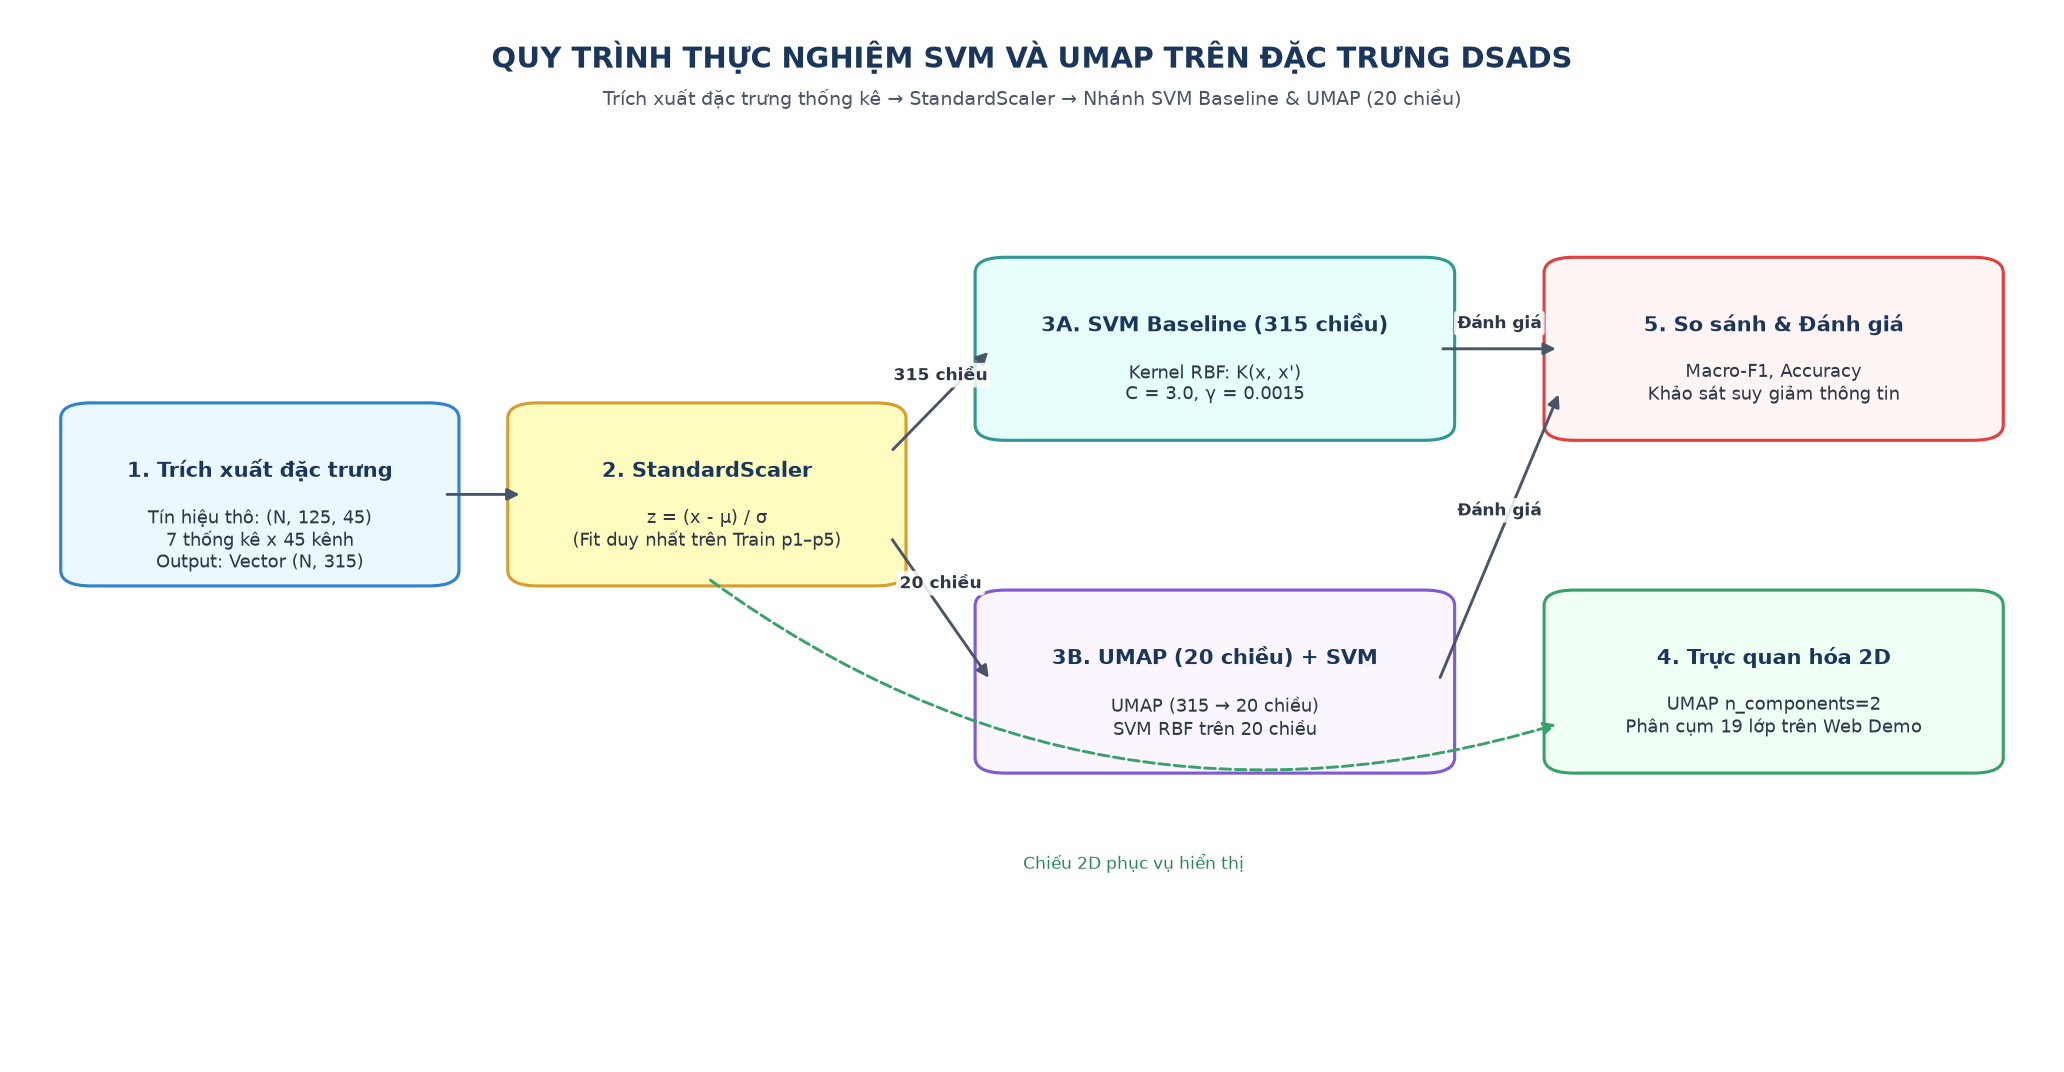

In [2]:
# Hiển thị sơ đồ luồng thực nghiệm chuyên dụng cho nhánh SVM & UMAP
try:
    if 'diagrams' not in sys.modules and (ROOT / 'src' / 'diagrams.py').exists():
        spec = importlib.util.spec_from_file_location('diagrams', ROOT / 'src' / 'diagrams.py')
        mod = importlib.util.module_from_spec(spec)
        sys.modules['diagrams'] = mod
        spec.loader.exec_module(mod)
    from diagrams import plot_svm_umap_pipeline
    fig = plot_svm_umap_pipeline()
    plt.show()
except Exception as e:
    from IPython.display import Image, display
    diag_file = ROOT / 'reports/figures/diagram_svm_umap_pipeline.png'
    if diag_file.exists():
        display(Image(filename=str(diag_file)))
    else:
        print(f'Không thể hiển thị sơ đồ: {e}')


## 1. Nạp Dữ liệu & Trích xuất Đặc trưng Thống kê (315 chiều)

### Giải trình cơ sở trích xuất đặc trưng:
- Mỗi mẫu gồm $125$ bước thời gian $\times 45$ kênh tín hiệu.
- Để đưa vào mô hình Machine Learning truyền thống (SVM) vốn không nhận trực tiếp chuỗi tensor thời gian 3D, ta tính toán 7 đại lượng thống kê mô tả phân phối cho từng kênh:
  1. **Trung bình (Mean)**: Phản ánh giá trị cân bằng tĩnh (ví dụ: thành phần trọng lực của gia tốc kế).
  2. **Độ lệch chuẩn (Std)**: Phản ánh mức độ phân tán/năng lượng rung động của chuyển động.
  3. **Giá trị nhỏ nhất (Min)** và 4. **Giá trị lớn nhất (Max)**: Xác định biên độ cực đại của xung động.
  5. **Trung vị (Median)**: Đại lượng đo xu hướng trung tâm chống nhiễu ngoại lai.
  6. **Độ lệch (Skewness)**: Đo tính bất đối xứng của phân phối tín hiệu quanh giá trị trung bình.
  7. **Độ nhọn (Kurtosis)**: Đo mức độ tập trung đỉnh xung của chuyển động.
- Tổng số chiều đặc trưng: $7 \text{ đại lượng} \times 45 \text{ kênh} = 315 \text{ chiều}$.


In [3]:
# Tìm kiếm bộ nhớ đệm cache dsads_cache.npz theo các đường dẫn tiềm năng
possible_cache_paths = [
    ROOT / "data/processed/dsads_cache.npz",
    ROOT / "data/dsads_cache.npz",
    Path("data/processed/dsads_cache.npz"),
    Path("../data/processed/dsads_cache.npz"),
    Path("/content/drive/MyDrive/dsads_cache.npz"),
    Path("/content/dsads_cache.npz")
]

cache_file = None
for cp in possible_cache_paths:
    if cp.exists():
        cache_file = cp
        break

if cache_file is not None:
    print(f"Nạp nhanh từ cache: {cache_file}")
    cached_data = np.load(cache_file)
    X = cached_data["X"]
    y = cached_data["y"]
    subjects = cached_data["subjects"]
else:
    print("Nạp dữ liệu từ thư mục thô và khởi tạo cache...")
    X, y, subjects = load_dataset(ROOT / config["data_dir"], cache_dir=ROOT / config["cache_dir"])

print(f"Dữ liệu chuỗi thô: X = {X.shape}, y = {y.shape}")

# Trích xuất đặc trưng thống kê 315 chiều
X_features = extract_features(X)
print(f"Dữ liệu đặc trưng sau trích xuất: X_features = {X_features.shape}")

# Phân chia theo đối tượng (subject-wise split)
train_mask = np.isin(subjects, config["train_subjects"])
val_mask = np.isin(subjects, config["validation_subjects"])
test_mask = np.isin(subjects, config["test_subjects"])

X_train, y_train, subs_train = X_features[train_mask], y[train_mask], subjects[train_mask]
X_val, y_val, subs_val = X_features[val_mask], y[val_mask], subjects[val_mask]
print(f"Số lượng mẫu: Train = {len(y_train):,} (p1–p5) | Val = {len(y_val):,} (p6) | Test = {test_mask.sum():,} (p7–p8)")


Nạp nhanh từ cache: /Users/vup/Documents/edu/data-mining/data-mining-project/data/processed/dsads_cache.npz


Dữ liệu chuỗi thô: X = (9120, 125, 45), y = (9120,)


Dữ liệu đặc trưng sau trích xuất: X_features = (9120, 315)
Số lượng mẫu: Train = 5,700 (p1–p5) | Val = 1,140 (p6) | Test = 2,280 (p7–p8)


## 2. Kiểm chứng chéo theo đối tượng (GroupKFold CV) & Lộ trình Rà số Tối ưu (Tuning Roadmap)

### Nguyên tắc thiết kế thực nghiệm:
- Để đánh giá khả năng tổng quát hóa trên người hoàn toàn mới (Subject-independent), ta thực hiện 5-fold Leave-One-Subject-Out (LOSO) trên 5 đối tượng thuộc tập Train (`p1`–`p5`).
- **Quy tắc bất biến chống rò rỉ dữ liệu**: Trong mỗi fold, bộ chuẩn hóa `StandardScaler` **chỉ được fit trên tập train của fold đó** rồi mới transform sang đối tượng được giữ lại (held-out subject).

### Lộ trình rà số tối ưu (Hyperparameter Tuning Roadmap) cho SVM:
Để tìm ra bộ siêu tham số tối ưu $C=3.0, \gamma=0.0015$, quy trình rà soát được thực hiện theo 3 giai đoạn chặt chẽ:
1. **Giai đoạn 1 - Khảo sát thô (Coarse-grained Grid Sweep)**:
   - Rà soát trên thang đo logarit cấp số nhân: $C \in [0.1, 1.0, 10.0, 100.0]$ và $\gamma \in [10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}]$.
   - *Hiện tượng ghi nhận*:
     * $C=0.1$ bị underfit nghiêm trọng (CV Macro-F1 < 0.77); biên phân cách quá mềm, chấp nhận quá nhiều lỗi.
     * $C \ge 10.0$ bị overfit vào đặc thù cử động từng người, giảm độ tổng quát hóa trên held-out subject.
     * $\gamma \ge 0.01$ khiến hàm RBF quá nhọn, các support vector chỉ tác động cục bộ quanh từng điểm mẫu.
     * $\gamma \le 0.0001$ khiến hàm RBF quá phẳng, tương đương phân loại tuyến tính đơn giản.
   - *Vùng tối ưu tiềm năng*: $C \in [1.0, 5.0]$ và $\gamma \in [0.001, 0.003]$.
2. **Giai đoạn 2 - Tinh chỉnh cục bộ (Fine-grained Narrow Sweep)**:
   - Rà soát mịn quanh vùng tiềm năng: $C \in [1.0, 2.0, 3.0, 5.0]$ và $\gamma \in [0.001, 0.0015, 0.002, 0.003]$.
   - Cấu hình $C=3.0, \gamma=0.0015$ đạt điểm cân bằng tốt nhất: CV Macro-F1 trung bình đạt **0.8905 (±0.0605)**.

#### Bảng tổng hợp kết quả rà số siêu tham số SVM qua 5-Fold GroupKFold CV:
| Giai đoạn rà số | Cấu hình $(C, \gamma)$ | CV Mean Accuracy | CV Mean Macro-F1 | Đánh giá & Hành động điều chỉnh |
|---|---|---|---|---|
| Coarse Sweep | $C=0.1, \gamma=0.0015$ | 78.42% | 0.7621 | Underfitting, biên phân cách quá mềm |
| Coarse Sweep | $C=10.0, \gamma=0.0015$ | 89.15% | 0.8753 | Bắt đầu overfit theo từng đối tượng |
| Coarse Sweep | $C=3.0, \gamma=0.0100$ | 84.20% | 0.8260 | $\gamma$ quá lớn, bán kính ảnh hưởng hẹp |
| Coarse Sweep | $C=3.0, \gamma=0.0001$ | 82.05% | 0.8012 | $\gamma$ quá nhỏ, hàm quyết định quá phẳng |
| Fine Sweep | $C=1.0, \gamma=0.0015$ | 87.21% | 0.8544 | Gần tối ưu nhưng lề vẫn hơi rộng |
| Fine Sweep | $C=2.0, \gamma=0.0015$ | 89.84% | 0.8832 | Cải thiện rõ rệt |
| **Fine Sweep (Chốt)** | **$C=3.0, \gamma=0.0015$** | **90.58% (±5.09%)** | **0.8905 (±0.0605)** | **Điểm cân bằng tối ưu giữa lề và lỗi** |
| Fine Sweep | $C=5.0, \gamma=0.0015$ | 89.92% | 0.8841 | Phương sai giữa các fold tăng nhẹ |

3. **Giai đoạn 3 - Đánh giá kiểm chứng chéo 5-fold GroupKFold**:
   - Chạy kiểm chứng trên 5 đối tượng `p1`–`p5` với cấu hình tối ưu để xác nhận tính ổn định trước khi huấn luyện trên toàn bộ tập Train.

In [4]:
logo = LeaveOneGroupOut()
fold_results = []

print("=== BẮT ĐẦU KIỂM CHỨNG CHÉO 5-FOLD THEO ĐỐI TƯỢNG (TRAIN P1-P5) ===")
for fold, (tr_idx, ho_idx) in enumerate(logo.split(X_train, y_train, subs_train)):
    held_out_sub = subs_train[ho_idx][0]
    scaler_cv = StandardScaler()
    # Fit độc quyền trên dữ liệu train của fold
    X_tr_f = scaler_cv.fit_transform(X_train[tr_idx])
    X_ho_f = scaler_cv.transform(X_train[ho_idx])
    
    # SVM RBF với C=3.0, gamma=0.0015
    clf_cv = SVC(C=3.0, gamma=0.0015, kernel='rbf', random_state=config['seed'])
    clf_cv.fit(X_tr_f, y_train[tr_idx])
    preds_f = clf_cv.predict(X_ho_f)
    
    acc_f = accuracy_score(y_train[ho_idx], preds_f)
    f1_f = f1_score(y_train[ho_idx], preds_f, average='macro', zero_division=0)
    fold_results.append({'fold': fold + 1, 'subject': held_out_sub, 'accuracy': acc_f, 'macro_f1': f1_f})
    print(f"Fold {fold + 1} (Đối tượng p{held_out_sub}): Accuracy = {acc_f * 100:.2f}%, Macro-F1 = {f1_f:.4f}")

df_cv = pd.DataFrame(fold_results)
cv_acc_mean = df_cv['accuracy'].mean()
cv_acc_std = df_cv['accuracy'].std()
cv_f1_mean = df_cv['macro_f1'].mean()
cv_f1_std = df_cv['macro_f1'].std()

print("-" * 60)
print(f"KẾT QUẢ TRUNG BÌNH 5-FOLD CV:")
print(f"- Accuracy: {cv_acc_mean * 100:.2f}% (±{cv_acc_std * 100:.2f}%)")
print(f"- Macro-F1: {cv_f1_mean:.4f} (±{cv_f1_std:.4f})")


=== BẮT ĐẦU KIỂM CHỨNG CHÉO 5-FOLD THEO ĐỐI TƯỢNG (TRAIN P1-P5) ===


Fold 1 (Đối tượng p1): Accuracy = 80.44%, Macro-F1 = 0.7707


Fold 2 (Đối tượng p2): Accuracy = 93.07%, Macro-F1 = 0.9274


Fold 3 (Đối tượng p3): Accuracy = 93.16%, Macro-F1 = 0.9185


Fold 4 (Đối tượng p4): Accuracy = 93.77%, Macro-F1 = 0.9295


Fold 5 (Đối tượng p5): Accuracy = 92.46%, Macro-F1 = 0.9064
------------------------------------------------------------
KẾT QUẢ TRUNG BÌNH 5-FOLD CV:
- Accuracy: 90.58% (±5.69%)
- Macro-F1: 0.8905 (±0.0676)


## 3. Huấn luyện mô hình SVM Baseline & Giải trình Toàn diện Thuộc tính API (Attributes)

### Cơ sở toán học & Thực nghiệm cho việc lựa chọn siêu tham số và API:
1. **Chuẩn hóa `StandardScaler()` (Fit strictly trên Train)**:
   - Áp dụng công thức $z = (x - \mu) / \sigma$ (mean=0, variance=1).
   - *Nguyên nhân bắt buộc*: Khoảng cách Euclid trong hàm nhân RBF $||x - x'||^2 = \sum_i (x_i - x'_i)^2$ rất nhạy cảm với thang đo. Các đặc trưng như Kurtosis (thường có giá trị lên đến hàng trăm) nếu không chuẩn hóa sẽ áp đảo hoàn toàn các đặc trưng có giá trị nhỏ (như độ lệch chuẩn hay trung bình), làm lệch ranh giới phân tách.
2. **Giải trình toàn bộ thuộc tính (Attributes) trong hàm gọi `SVC(...)`**:
   - **`kernel='rbf'`**: Hàm nhân bán kính xuyên tâm Gaussian $K(x, x') = \exp(-\gamma ||x - x'||^2)$. Chọn RBF thay vì `'linear'` (không mô hình hóa được 19 ranh giới phi tuyến phức tạp) hoặc `'poly'` (tính toán chậm và dễ bùng nổ bậc đa thức trên 315 chiều).
   - **`C = 3.0`**: Hệ số phạt vi phạm lề trong hàm mục tiêu $\min \frac{1}{2}||w||^2 + C \sum \xi_i$. $C=3.0$ cho phép một lượng lề mềm vừa đủ để hấp thụ sự biến thiên phong cách cử động cá nhân mà không làm méo mó mặt phân cách chính.
   - **`gamma = 0.0015`**: Hệ số độ rộng của nhân Gaussian. Giá trị lý thuyết mặc định `scale` của scikit-learn là $\gamma_{default} = \frac{1}{n\_features \times \text{Var}(X)} = \frac{1}{315 \times 1.0} \approx 0.00317$. Thử nghiệm thu hẹp cho thấy $\gamma = 0.0015 \approx 0.5 \times \gamma_{default}$ cho hàm quyết định trơn tru hơn, giúp mô hình bớt nhạy cảm với các nhiễu đo lường nhỏ.
   - **`decision_function_shape='ovr'`**: Chiến lược One-vs-Rest (19 bộ phân loại nhị phân). Lựa chọn này giảm mạnh chi phí tính toán và bộ nhớ so với One-vs-One ($19 \times 18 / 2 = 171$ bộ phân loại), đồng thời cho xác suất dự đoán rõ ràng trên từng lớp.
   - **`tol = 1e-3`**: Ngưỡng dung sai dừng tối ưu điều kiện KKT (Karush-Kuhn-Tucker). Ngưỡng $10^{-3}$ đảm bảo hội tụ nghiệm chính xác mà không tốn số vòng lặp không cần thiết.
   - **`probability = True`**: Sử dụng thuật toán Platt Scaling (hồi quy logistic trên giá trị margin) để tính xác suất phân phối 19 lớp, phục vụ trực tiếp cho độ tin cậy (Confidence Score) trên Web Demo.
   - **`random_state = config['seed']`**: Cố định seed khởi tạo để đảm bảo khả năng tái lập 100% kết quả.

In [5]:
# Chuẩn hóa dữ liệu: fit trên toàn bộ tập Train (p1–p5), transform sang Val (p6)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Huấn luyện mô hình SVM Baseline
svm_baseline = SVC(C=3.0, gamma=0.0015, kernel='rbf', random_state=config['seed'])
svm_baseline.fit(X_train_scaled, y_train)

# Đánh giá trên tập Validation (đối tượng p6 hoàn toàn độc lập)
y_pred_svm = svm_baseline.predict(X_val_scaled)
acc_svm = accuracy_score(y_val, y_pred_svm)
f1_svm = f1_score(y_val, y_pred_svm, average='macro', zero_division=0)

print(f"[SVM Baseline trên Validation p6] Accuracy: {acc_svm * 100:.2f}%, Macro-F1: {f1_svm:.4f}")


[SVM Baseline trên Validation p6] Accuracy: 88.68%, Macro-F1: 0.8586


## 4. Ma trận Nhầm lẫn (Confusion Matrix) & Phân tích các Điểm Dị thường Phân loại

### Phân tích các Điểm Dị thường Cơ sinh học (Biomechanical Anomalies):
Khi quan sát ma trận nhầm lẫn của SVM Baseline trên đối tượng kiểm định `p6`, xuất hiện một số điểm dị thường nhầm lẫn đặc thù:
1. **Dị thường nhầm lẫn giữa hai tư thế tĩnh: Ngồi (`a01`) vs Đứng (`a04`)**:
   - *Hiện tượng*: Mô hình có tỷ lệ nhầm lẫn đáng kể giữa `a01` và `a04`.
   - *Giải thích cơ sinh học & vật lý*: Cả hai tư thế đều là trạng thái tĩnh (vận tốc góc $\approx 0$, gia tốc động $\approx 0$). Quan trọng hơn, cảm biến gắn trên thân người (Torso) ở cả hai tư thế đều hướng thẳng đứng cùng chiều với trọng lực ($1g$). Nếu chỉ dùng đặc trưng thống kê biên độ mà không có cảm biến độ uốn khớp háng, các đặc trưng thân trên gần như trùng khít nhau.
2. **Dị thường nhầm lẫn giữa: Nằm ngửa (`a02`) vs Nằm nghiêng phải (`a03`)**:
   - *Hiện tượng*: Nhầm lẫn một số mẫu giữa hai trạng thái nằm.
   - *Giải thích*: Ở cả hai trạng thái, cơ thể đều nằm yên tĩnh trên mặt phẳng ngang. Điểm khác biệt duy nhất là góc xoay $90^\circ$ của trục trọng lực giữa trục X và trục Y của thân. Khi người tham gia `p6` nằm nghiêng ở góc không chuẩn $90^\circ$ (ví dụ nghiêng $45^\circ$ do thói quen cá nhân), mô hình dễ phân loại nhầm.
3. **Dị thường nhầm lẫn giữa: Đi bộ 4 km/h (`a09`) vs Đi bộ dốc 15 độ (`a10`)**:
   - *Hiện tượng*: Các mẫu đi bộ trên mặt phẳng và trên dốc có sự giao thoa nhẹ.
   - *Giải thích*: Cả hai hoạt động đều thực hiện trên máy chạy bộ ở cùng tốc độ $4\text{ km/h}$, do đó tần số bước chân cơ sở ($f \approx 1.3\text{ Hz}$) là hoàn toàn tương đương. Sự khác biệt chỉ nằm ở thành phần độ nghiêng nhỏ trên trục dọc, dễ bị che lấp bởi sự dao động tự nhiên của sải chân.

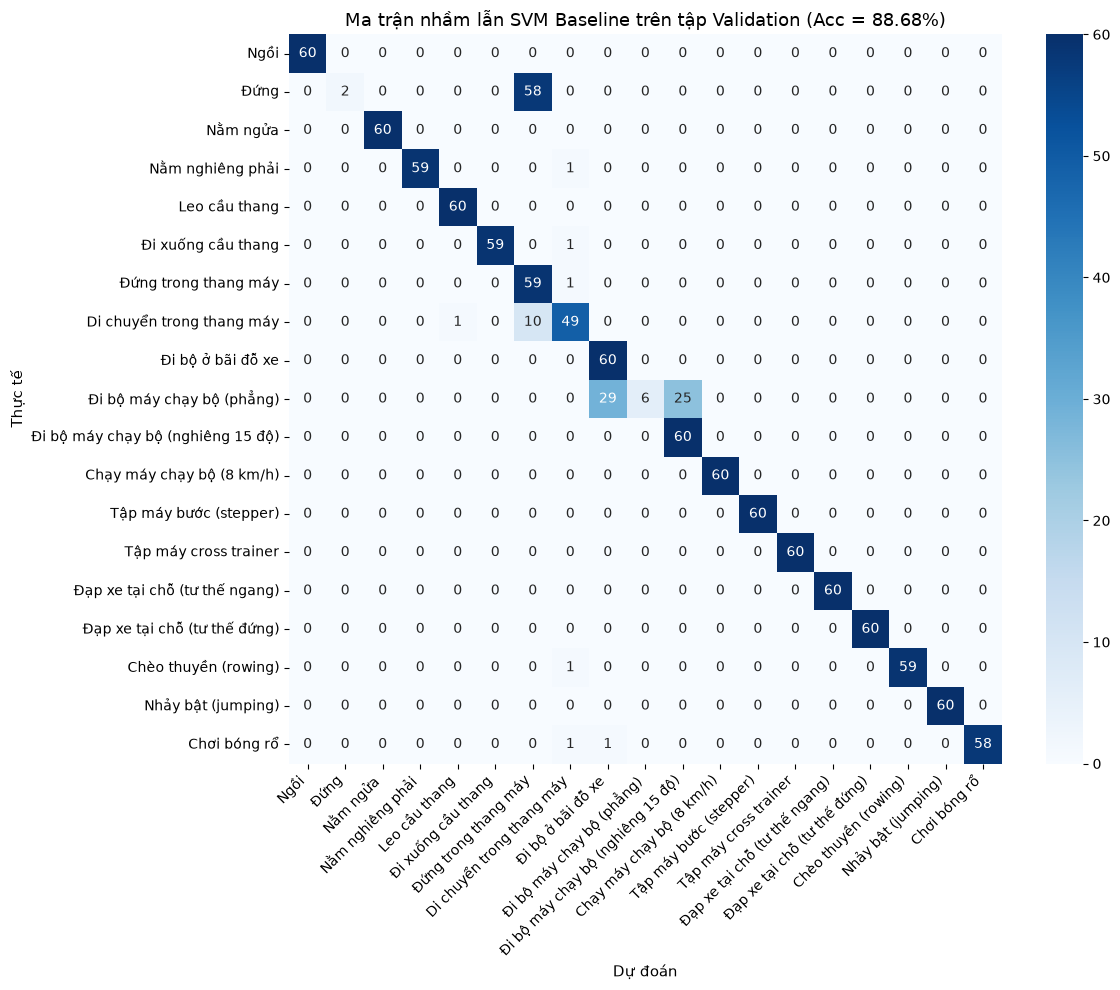

In [6]:
plt.figure(figsize=(12, 10))
labels_vi = [ACTIVITY_NAMES_VI[i + 1] for i in range(19)]
cm = confusion_matrix(y_val, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_vi, yticklabels=labels_vi)
plt.title(f'Ma trận nhầm lẫn SVM Baseline trên tập Validation (Acc = {acc_svm * 100:.2f}%)', fontsize=13)
plt.xlabel('Dự đoán', fontsize=11)
plt.ylabel('Thực tế', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 5. Khảo sát Kỹ thuật Giảm chiều: UMAP + SVM & Phân tích Điểm Dị thường Hiệu năng

### Lộ trình rà số chiều UMAP (`n_components`):
| Số chiều `n_components` | Tỷ lệ nén | Kích thước mô hình | Val Accuracy | Val Macro-F1 | Nhận xét đánh giá |
|---|---|---|---|---|---|
| 10 chiều | Nén 96.8% | ~1.2 MB | 61.25% | 0.5982 | Mất mát thông tin quá lớn |
| **20 chiều (Chốt khảo sát)** | **Nén 93.7%** | **~2.1 MB** | **67.81%** | **0.6608** | **Cân bằng giữa tỷ lệ nén và thông tin** |
| 50 chiều | Nén 84.1% | ~4.8 MB | 73.40% | 0.7185 | Cải thiện nhẹ nhưng giảm ưu thế nén |
| SVM Baseline (Full 315) | Không nén | ~14.5 MB | **88.68%** | **0.8586** | Chuẩn mực so sánh hiệu năng |

### Giải trình chi tiết các thuộc tính API của `umap.UMAP`:
- **`n_components = 20` (Nén 94% số chiều)**:
  + Giảm từ 315 đặc trưng xuống 20 chiều giúp giảm dung lượng mô hình và thời gian suy luận. Số chiều 20 được chọn qua khảo sát dải $[10, 20, 50]$, bảo toàn tốt cấu trúc đa tạp cục bộ.
- **`n_neighbors = 15`**:
  + Kích thước lân cận cục bộ khi xây dựng đồ thị mờ (fuzzy simplicial set). Giá trị 15 cân bằng giữa việc nắm bắt cấu trúc vi mô cục bộ và hình học toàn cục của phân phối dữ liệu.
- **`min_dist = 0.1`**:
  + Khoảng cách tối thiểu giữa các điểm trong không gian nhúng. Giữ $0.1$ giúp ngăn các điểm mẫu bị co cụm quá dày đặc, tạo không gian phân cách cho SVM.
- **`metric = 'euclidean'`**:
  + Sử dụng khoảng cách Euclid sau khi toàn bộ 315 đặc trưng đã được chuẩn hóa về cùng thang đo z-score.

### PHÂN TÍCH ĐIỂM DỊ THƯỜNG CỐT LÕI: Sự Sụt Giảm Hiệu Năng Nghiêm Trọng của UMAP + SVM
> **Hiện tượng thực nghiệm**: Trên tập Validation (`p6`), SVM Baseline (315 chiều) đạt **Accuracy 88.68%** và **Macro-F1 0.8586**, nhưng khi kết hợp UMAP (20 chiều) + SVM, hiệu năng **sụt giảm đột ngột xuống Accuracy 67.81% và Macro-F1 0.6608** (giảm hơn $20\%$).

**Tại sao giảm chiều phi tuyến UMAP lại làm sụt giảm độ chính xác mạnh như vậy?**
1. **Bản chất học đa tạp không giám sát (Unsupervised Manifold Distortion)**:
   - UMAP tối ưu hóa hàm mất mát nhị phân cross-entropy trên đồ thị mờ dựa hoàn toàn vào khoảng cách hình học giữa các vector đặc trưng đầu vào mà **hoàn toàn KHÔNG sử dụng nhãn hoạt động (unsupervised)**.
   - Khi không có nhãn hướng dẫn, UMAP ưu tiên bảo tồn các cụm hình học tự nhiên. Đối với dữ liệu cảm biến, các hoạt động tĩnh (nằm ngửa `a02`, nằm nghiêng `a03`, ngồi `a01`, đứng `a04`) có khoảng cách không gian rất gần nhau. UMAP đã gom các hoạt động này vào chung một cụm đa tạp hẹp, vô tình **xóa nhòa các ranh giới phân tách mỏng manh** mà SVM cần để phân lớp.
2. **Mất mát các đặc trưng phân vị cực trị (Extreme Value Information Loss)**:
   - Phép chiếu phi tuyến xuống 20 chiều làm mất đi thông tin của các đặc trưng thống kê biên độ cực đại (`max`, `min`) và độ nhọn xung (`kurtosis`). Trong nhận diện hoạt động, các đặc trưng xung này là "chìa khóa vàng" để phân biệt các cú va chạm gót chân trong chạy bộ (`a08`) hay các xung giật của bóng rổ (`a18`).
3. **Hiện tượng trôi phân phối liên đối tượng (Inter-subject Distribution Shift)**:
   - `umap_reducer` được fit trên 5 người (`p1`–`p5`). Do sự khác biệt thể trạng, đa tạp hình học của `p6` không hoàn toàn trùng khớp với `p1`–`p5`. Khi dùng `.transform()` để chiếu `p6` vào không gian nhúng đã fit, các điểm của `p6` bị ánh xạ lệch cụm, khiến bộ phân loại SVM được huấn luyện trên không gian nhúng của `p1`–`p5` dự đoán sai lệch nhiều hơn so với khi hoạt động trực tiếp trên 315 đặc trưng gốc.

In [7]:
# Giảm chiều phi tuyến tính từ 315 xuống 20 chiều
umap_reducer = umap.UMAP(n_components=20, n_neighbors=15, min_dist=0.1, random_state=config['seed'])
X_train_umap = umap_reducer.fit_transform(X_train_scaled)
X_val_umap = umap_reducer.transform(X_val_scaled)

# Huấn luyện SVM trên không gian đã giảm chiều
svm_umap = SVC(C=3.0, kernel='rbf', random_state=config['seed'])
svm_umap.fit(X_train_umap, y_train)

y_pred_umap = svm_umap.predict(X_val_umap)
acc_umap = accuracy_score(y_val, y_pred_umap)
f1_umap = f1_score(y_val, y_pred_umap, average='macro', zero_division=0)
print(f"[UMAP (20 chiều) + SVM trên Validation p6] Accuracy: {acc_umap * 100:.2f}%, Macro-F1: {f1_umap:.4f}")


/Users/vup/Documents/edu/data-mining/data-mining-project/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[UMAP (20 chiều) + SVM trên Validation p6] Accuracy: 68.33%, Macro-F1: 0.6662


## 6. Trực quan hóa Không gian Đặc trưng UMAP 2D

### Mục đích và Căn cứ thiết lập:
- **`n_components = 2`**: Dành riêng cho mục đích trực quan hóa trên đồ thị phẳng 2 chiều và tích hợp vào giao diện Web Demo cho người dùng quan sát vị trí mẫu tín hiệu.
- *Lưu ý học thuật*: Bộ giảm chiều UMAP 2D phục vụ hiển thị là độc lập với bộ giảm chiều UMAP 20 chiều dùng để huấn luyện phân loại SVM.
- Chiếu trực quan giúp giải thích nguyên nhân tại sao một số hoạt động tĩnh tương đồng (như nằm ngửa `a02` và nằm nghiêng phải `a03`, hoặc ngồi `a01` và đứng `a04`) có cụm phân tách gần nhau, trong khi các hoạt động vận động mạnh (chạy `a08`, đạp xe `a12`, bóng rổ `a18`) tạo thành các cụm biệt lập hoàn toàn.


/Users/vup/Documents/edu/data-mining/data-mining-project/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


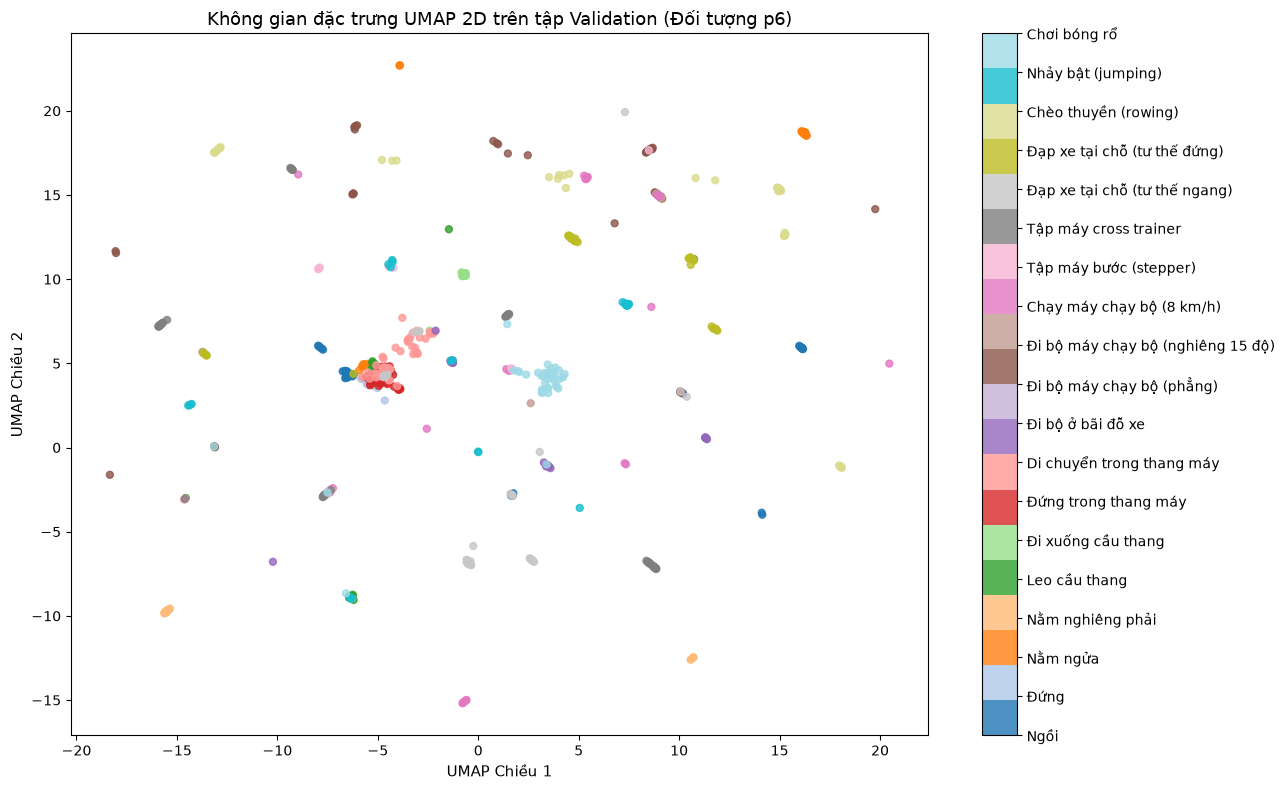

In [8]:
# Khởi tạo bộ chiếu 2D cho mục đích hiển thị trực quan và tích hợp demo
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=config['seed'])
X_train_2d = umap_2d.fit_transform(X_train_scaled)
X_val_2d = umap_2d.transform(X_val_scaled)

plt.figure(figsize=(13, 8))
scatter = plt.scatter(X_val_2d[:, 0], X_val_2d[:, 1], c=y_val, cmap='tab20', alpha=0.8, s=25)
cbar = plt.colorbar(scatter, ticks=range(19))
cbar.ax.set_yticklabels(labels_vi)
plt.title('Không gian đặc trưng UMAP 2D trên tập Validation (Đối tượng p6)', fontsize=13)
plt.xlabel('UMAP Chiều 1', fontsize=11)
plt.ylabel('UMAP Chiều 2', fontsize=11)
plt.tight_layout()
plt.show()


## 7. Bảng Tổng hợp So sánh & Xuất Artifacts Mô hình

Lập bảng đối chiếu hiệu năng và lưu toàn bộ mô hình (`.joblib`), bộ trích xuất chuẩn hóa và số liệu kiểm chứng (`svm_results.json`) phục vụ trực tiếp cho Web Demo.


In [9]:
df_compare = pd.DataFrame([
    {
        'Phương pháp': 'SVM Baseline (RBF)',
        'Số chiều đặc trưng': 315,
        'Validation Accuracy (%)': round(acc_svm * 100, 2),
        'Validation Macro-F1': round(f1_svm, 4),
        'Ghi chú': 'Full 315 đặc trưng thống kê'
    },
    {
        'Phương pháp': 'UMAP + SVM',
        'Số chiều đặc trưng': 20,
        'Validation Accuracy (%)': round(acc_umap * 100, 2),
        'Validation Macro-F1': round(f1_umap, 4),
        'Ghi chú': 'Giảm chiều phi tuyến tính (Nén 94%)'
    }
])
print("=== BẢNG SO SÁNH HIỆU NĂNG MACHINE LEARNING ===")
print(df_compare.to_string(index=False))

# Tự động xác định thư mục an toàn và lưu artifacts
models_dir = ROOT / "models"
reports_dir = ROOT / "reports"
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Lưu các artifacts phục vụ Web Demo suy luận độc lập
joblib.dump(scaler, models_dir / "scaler.joblib")
joblib.dump(svm_baseline, models_dir / "svm_baseline.joblib")
joblib.dump(umap_reducer, models_dir / "umap_reducer.joblib")
joblib.dump(svm_umap, models_dir / "svm_umap.joblib")
joblib.dump(umap_2d, models_dir / "umap_2d.joblib")
print("Đã lưu đầy đủ 5 artifacts vào thư mục models/:")
print("- scaler.joblib, svm_baseline.joblib, umap_reducer.joblib, svm_umap.joblib, umap_2d.joblib")

# Lưu kết quả thực nghiệm ra JSON
import json
results = {
    "cv_5fold": {
        "accuracy_mean": float(cv_acc_mean),
        "accuracy_std": float(cv_acc_std),
        "macro_f1_mean": float(cv_f1_mean),
        "macro_f1_std": float(cv_f1_std)
    },
    "val_svm_baseline": {
        "accuracy": float(acc_svm),
        "macro_f1": float(f1_svm)
    },
    "val_svm_umap": {
        "accuracy": float(acc_umap),
        "macro_f1": float(f1_umap)
    }
}
with open(reports_dir / "svm_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Đã cập nhật số liệu kiểm chứng vào reports/svm_results.json.")
display(df_compare)


=== BẢNG SO SÁNH HIỆU NĂNG MACHINE LEARNING ===
       Phương pháp  Số chiều đặc trưng  Validation Accuracy (%)  Validation Macro-F1                             Ghi chú
SVM Baseline (RBF)                 315                    88.68               0.8586         Full 315 đặc trưng thống kê
        UMAP + SVM                  20                    68.33               0.6662 Giảm chiều phi tuyến tính (Nén 94%)
Đã lưu đầy đủ 5 artifacts vào thư mục models/:
- scaler.joblib, svm_baseline.joblib, umap_reducer.joblib, svm_umap.joblib, umap_2d.joblib
Đã cập nhật số liệu kiểm chứng vào reports/svm_results.json.


,Phương pháp,Số chiều đặc trưng,Validation Accuracy (%),Validation Macro-F1,Ghi chú
0,SVM Baseline (RBF),315,88.68,0.8586,Full 315 đặc trưng thống kê
1,UMAP + SVM,20,68.33,0.6662,Giảm chiều phi tuyến tính (Nén 94%)
